# Audio in the frequency domain: from waveform to log-mel spectrogram

A microphone records **air pressure over time**: a single sequence of numbers. A lot of what we hear is in the
*frequencies* of that sequence instead. The pitch of a voice, the vowels, a whistle, the hum of a machine: each puts its
energy at particular frequencies, and that energy changes over time.

This notebook turns one short recording into the representation that most audio models use as input, the
**log-mel spectrogram**, one step at a time:

1. Load the waveform
2. Fourier transform of the whole clip: which frequencies are present, but not *when*
3. Cut the waveform into short overlapping frames and apply a window
4. Fourier transform of every frame: the spectrogram
5. Decibels: compress the huge range of values
6. The mel scale: frequencies the way people hear them
7. The mel filter bank
8. The mel spectrogram, then the log-mel spectrogram

Everything is computed with NumPy so that every step is visible. Libraries do the same in a single call
(`torchaudio.transforms.MelSpectrogram`, `librosa.feature.melspectrogram`), see the end.

The clip is a recording from the Assignment 3 dataset: 16 kHz mono mixtures of Freesound sounds.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import s3fs
from IPython.display import Audio, display

SAMPLE_RATE = 16000  # samples per second
DATA = 'danylo-ucla/speech-fraction/v1'

## 1. Load the waveform

Each dataset file `<segment>_x.npy` holds all recordings of a segment as one int16 array `[recordings, 160000]`
(10 s each, zero-padded at the end). The file is 640 MB, but we only need one row: we read the `.npy` header to find
where the data starts, then read just the bytes of that row from S3.

In [2]:
fs = s3fs.S3FileSystem()


def load_recording(segment, index):
    # The real length of each recording (before the zero padding) is in <segment>_y.parquet.
    samples = pd.read_parquet(f's3://{DATA}/{segment}_y.parquet').samples[index]
    with fs.open(f'{DATA}/{segment}_x.npy', 'rb', block_size=2**20) as f:
        np.lib.format.read_magic(f)
        (_, length), _, dtype = np.lib.format.read_array_header_1_0(f)
        row_bytes = length * dtype.itemsize
        f.seek(f.tell() + index * row_bytes)  # skip the header and the rows before this one
        row = np.frombuffer(f.read(row_bytes), dtype=dtype)
    return row[:samples] / 32768  # int16 -> float in [-1, 1]


wave = load_recording('validate', 4)
print(f'{len(wave)} samples = {len(wave) / SAMPLE_RATE:.2f} s, values from {wave.min():.3f} to {wave.max():.3f}')
display(Audio(wave, rate=SAMPLE_RATE))

121349 samples = 7.58 s, values from -0.392 to 0.422


Listen to it: background sounds and a buzzing tone first, then someone speaking from about 3.9 s.

The waveform is just the sequence of samples. Zoomed out, it shows **how loud** the sound is over time, but hardly
anything about **what** sound it is. Zoomed in to 30 ms, the oscillations become visible: speech is a mixture of
waves with different frequencies.

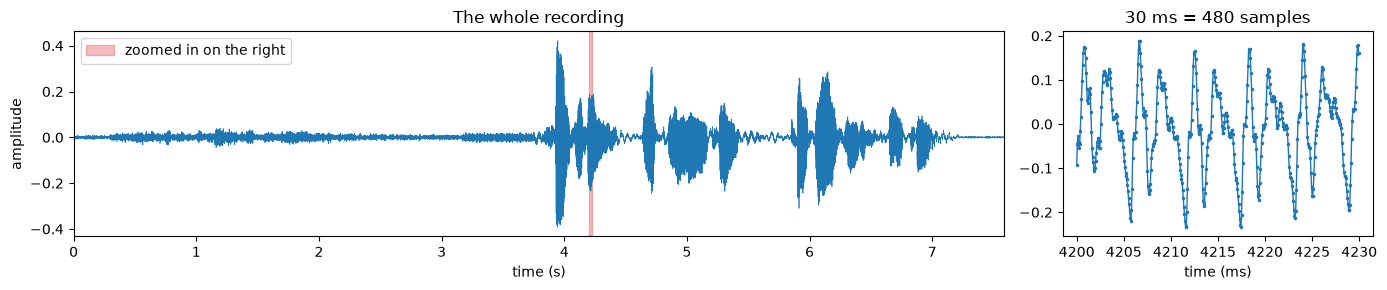

In [3]:
t = np.arange(len(wave)) / SAMPLE_RATE
fig, axes = plt.subplots(1, 2, figsize=(14, 3), gridspec_kw={'width_ratios': [3, 1]})

axes[0].plot(t, wave, lw=0.5)
axes[0].axvspan(4.2, 4.23, color='tab:red', alpha=0.3, label='zoomed in on the right')
axes[0].set(xlabel='time (s)', ylabel='amplitude', title='The whole recording', xlim=(0, t[-1]))
axes[0].legend(loc='upper left')

zoom = (t >= 4.2) & (t < 4.23)
axes[1].plot(t[zoom] * 1000, wave[zoom], '.-', lw=1, ms=3)
axes[1].set(xlabel='time (ms)', title='30 ms = 480 samples')
plt.tight_layout()
plt.show()

At 16,000 samples per second, the highest frequency the recording can represent is half of that, **8 kHz** (the
*Nyquist frequency*): a wave needs at least two samples per cycle. That is enough for speech, and it is why speech
datasets are often stored at 16 kHz (music is usually stored at 44.1 kHz).

## 2. Fourier transform of the whole clip

The **discrete Fourier transform** (DFT) rewrites a sequence of $N$ samples as a sum of sine waves at the frequencies
$k \cdot \frac{\text{sample rate}}{N}$, for $k = 0, \dots, N/2$. For each frequency it gives one complex number: its
absolute value is the **magnitude** of that sine wave (how much of it there is), its angle is the phase (where the
wave starts). The fast Fourier transform (FFT) is the fast algorithm that computes it, and `np.fft.rfft` is the
version for real-valued signals.

121349 samples -> 60675 complex numbers, frequencies from 0 to 8000 Hz in steps of 0.132 Hz


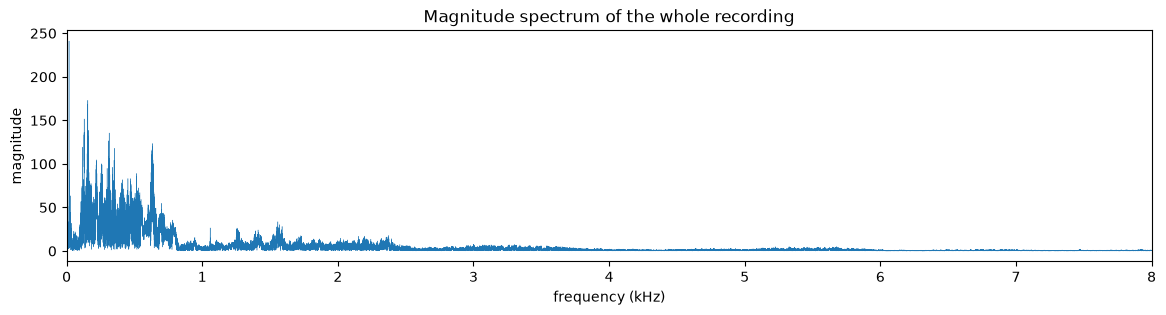

In [4]:
spectrum = np.fft.rfft(wave)
freqs = np.fft.rfftfreq(len(wave), d=1 / SAMPLE_RATE)
print(f'{len(wave)} samples -> {len(spectrum)} complex numbers, frequencies from 0 to {freqs[-1]:.0f} Hz '
      f'in steps of {freqs[1]:.3f} Hz')

plt.figure(figsize=(14, 3))
plt.plot(freqs / 1000, np.abs(spectrum), lw=0.3)
plt.xlabel('frequency (kHz)')
plt.ylabel('magnitude')
plt.title('Magnitude spectrum of the whole recording')
plt.xlim(0, 8)
plt.show()

Most of the energy is below 1 kHz, with sharp peaks from the steady tones in the recording. But the spectrum of the
whole clip has lost all information about **time**: we can't tell which frequencies belong to which sound, or when
anything happened. Sounds change every few tens of milliseconds, so instead we look at short pieces at a time.

## 3. Frames and windows

We cut the waveform into **frames** of 25 ms (400 samples), starting a new frame every 10 ms (160 samples), so
neighboring frames overlap. These are the most common choices for speech: a frame is short enough that the sound
barely changes within it, and long enough to contain several periods of a voice (whose pitch is about 85-255 Hz).

In [5]:
FRAME_LENGTH = 400  # 25 ms
HOP_LENGTH = 160    # 10 ms

# All windows of 400 consecutive samples, keeping every 160th one: [frames, 400]
frames = np.lib.stride_tricks.sliding_window_view(wave, FRAME_LENGTH)[::HOP_LENGTH]
frame_times = (np.arange(len(frames)) * HOP_LENGTH + FRAME_LENGTH / 2) / SAMPLE_RATE  # center of each frame
print('frames:', frames.shape)

frames: (756, 400)


Cutting a frame out of the waveform creates jumps at its edges: the wave starts and ends abruptly. The Fourier
transform sees these jumps as extra frequencies that are not in the sound (**spectral leakage**). To avoid that, each
frame is multiplied by a **window** that fades it in and out. The **Hann window** is a common choice:
$w[n] = \frac{1}{2}\left(1 - \cos\frac{2 \pi n}{L}\right)$, for $n = 0, \dots, L-1$.

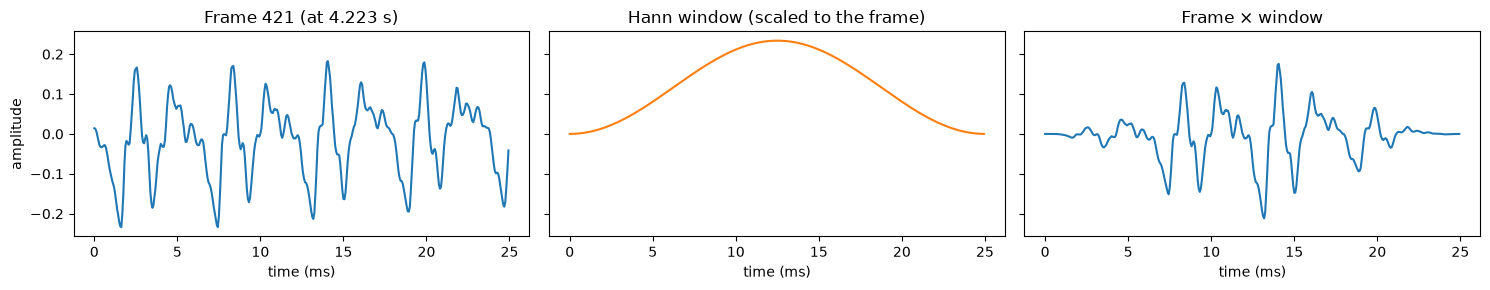

In [6]:
window = np.hanning(FRAME_LENGTH + 1)[:-1]  # the 'periodic' Hann window, as in torch.hann_window
frame_index = np.searchsorted(frame_times, 4.215)  # a frame in the middle of a word
frame = frames[frame_index]
ms = np.arange(FRAME_LENGTH) / SAMPLE_RATE * 1000

fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=True)
axes[0].plot(ms, frame)
axes[0].set(title=f'Frame {frame_index} (at {frame_times[frame_index]:.3f} s)', xlabel='time (ms)', ylabel='amplitude')
axes[1].plot(ms, window * np.abs(frame).max(), color='tab:orange')
axes[1].set(title='Hann window (scaled to the frame)', xlabel='time (ms)')
axes[2].plot(ms, frame * window)
axes[2].set(title='Frame × window', xlabel='time (ms)')
plt.tight_layout()
plt.show()

Now the Fourier transform of a single frame. We use an FFT size of 512, the next power of two above 400 (the FFT is
fastest for powers of two): the frame is padded with zeros to 512 samples. This gives $512 / 2 + 1 = 257$ frequencies,
spaced $16000 / 512 = 31.25$ Hz apart.

The frame is voiced speech, so its spectrum is a row of evenly spaced peaks, about 170 Hz apart: the **harmonics**
of the voice, at multiples of its pitch. Without the window, leakage fills the valleys between the harmonics.

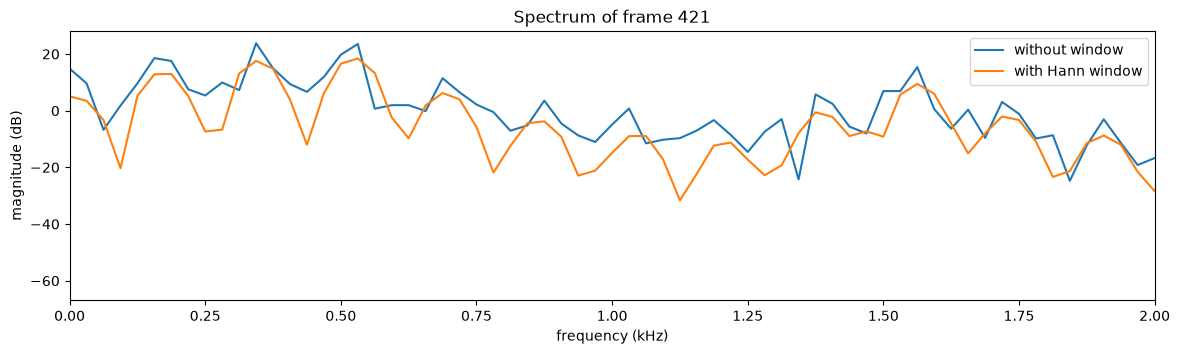

In [7]:
N_FFT = 512
bin_freqs = np.fft.rfftfreq(N_FFT, d=1 / SAMPLE_RATE)  # 257 frequencies, 0 to 8000 Hz

plt.figure(figsize=(14, 3.5))
for x, label in [(frame, 'without window'), (frame * window, 'with Hann window')]:
    magnitude = np.abs(np.fft.rfft(x, n=N_FFT))
    plt.plot(bin_freqs / 1000, 20 * np.log10(magnitude + 1e-10), label=label)
plt.xlabel('frequency (kHz)')
plt.ylabel('magnitude (dB)')
plt.title(f'Spectrum of frame {frame_index}')
plt.xlim(0, 2)
plt.legend()
plt.show()

(This plot is in decibels already, see step 5. Without them, everything except the tallest peaks would be flat.)

## 4. The spectrogram

Doing this for every frame gives the **short-time Fourier transform** (STFT): one spectrum per frame. The squared
magnitude is the **power** of each frequency in each frame. Stacked side by side, the spectra form the **spectrogram**:
time on the x axis, frequency on the y axis, power as color.

STFT: (756, 257) complex128 -> power: (756, 257)


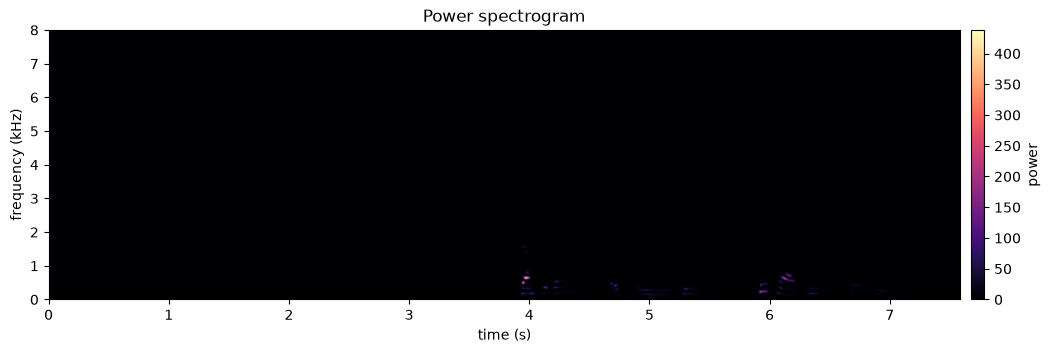

In [8]:
stft = np.fft.rfft(frames * window, n=N_FFT, axis=1)  # [frames, 257] complex
power = np.abs(stft) ** 2                            # [frames, 257]
print('STFT:', stft.shape, stft.dtype, '-> power:', power.shape)


def show(image, title, ylabel='frequency (kHz)', extent_y=(0, SAMPLE_RATE / 2000), colorbar='', ax=None):
    # image: [frames, bins]; displayed with time on the x axis and the low bins at the bottom.
    ax = ax or plt.figure(figsize=(14, 3.5)).gca()
    im = ax.imshow(image.T, origin='lower', aspect='auto', cmap='magma',
                   extent=[0, len(wave) / SAMPLE_RATE, *extent_y])
    ax.set(xlabel='time (s)', ylabel=ylabel, title=title)
    plt.colorbar(im, ax=ax, label=colorbar, pad=0.01)
    return ax


show(power, 'Power spectrogram', colorbar='power')
plt.show()

Almost all of it is black. Power values range over many orders of magnitude: a few loud moments at low frequencies are
millions of times stronger than everything else, so on a linear color scale nothing else is visible.

## 5. Decibels

Human hearing is roughly logarithmic: a sound with 10 times the power sounds about twice as loud, not 10 times as
loud. Audio is therefore measured in **decibels**: $\text{dB} = 10 \log_{10}(\text{power})$, so that every factor of
10 in power adds 10 dB. A small constant keeps silent bins away from $\log(0)$.

power from 1.7e-13 to 4.4e+02 -> -100 to 26 dB


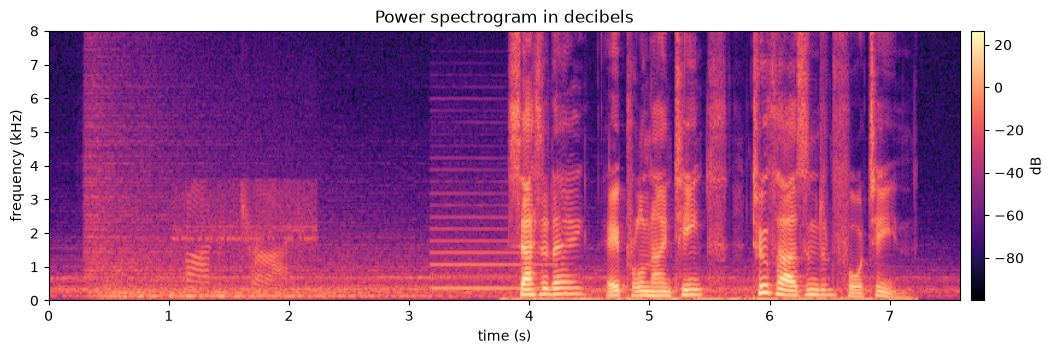

In [9]:
power_db = 10 * np.log10(power + 1e-10)
print(f'power from {power.min():.1e} to {power.max():.1e} -> {power_db.min():.0f} to {power_db.max():.0f} dB')
show(power_db, 'Power spectrogram in decibels', colorbar='dB')
plt.show()

Now the structure is visible:

- **0.3-3.2 s**: background sound, with a few long horizontal lines below 2 kHz: steady tones, like a hum.
- **1.1-2.2 s**: fainter harmonics that bend up and down, cut off above 3.6 kHz: this looks like a quieter voice,
  recorded at a lower sample rate.
- **3.2-3.9 s**: evenly spaced horizontal lines all the way up to 8 kHz: a buzzing tone, one constant pitch with many
  harmonics.
- **3.9-7.3 s**: speech. Each word is a burst of stacked harmonics that bend as the pitch of the voice changes; dark
  gaps are pauses between words; vertical smudges up to 8 kHz are consonants like *s*, *t*, *k*, which are noise
  rather than tones.

## 6. The mel scale

The spectrogram spends its 257 rows evenly on 0-8 kHz: 31.25 Hz each. Hearing doesn't work that way. We easily tell
apart 200 Hz from 300 Hz, but 7,200 Hz from 7,300 Hz sound almost the same. The **mel scale** is a perceptual scale of
pitch: equal steps in mels sound like equal steps in pitch. A common formula is

$$m = 2595 \log_{10}\left(1 + \frac{f}{700}\right)$$

It is close to linear below about 1 kHz and logarithmic above.

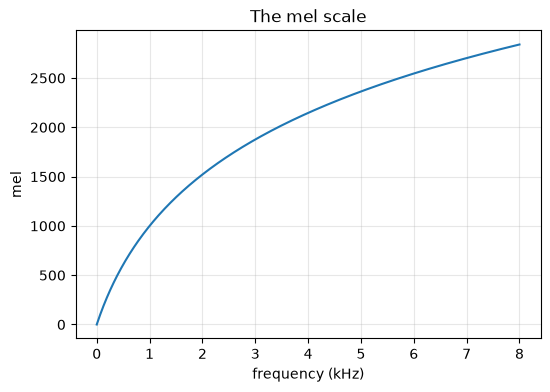

In [10]:
def hz_to_mel(f):
    return 2595 * np.log10(1 + f / 700)


def mel_to_hz(m):
    return 700 * (10 ** (m / 2595) - 1)


f = np.linspace(0, SAMPLE_RATE / 2, 500)
plt.figure(figsize=(6, 4))
plt.plot(f / 1000, hz_to_mel(f))
plt.xlabel('frequency (kHz)')
plt.ylabel('mel')
plt.title('The mel scale')
plt.grid(alpha=0.3)
plt.show()

## 7. The mel filter bank

To move the spectrogram to the mel scale, we choose a number of **mel bands** (64 here; 40 to 128 are common) with
center frequencies **evenly spaced in mels**, between 0 Hz and 8 kHz. Each band is a **triangular filter**: it rises
from the center of the band below it to its own center, then falls to the center of the band above it. The power of a
band is the weighted sum of the power of the STFT frequencies under its triangle.

Because the centers are evenly spaced in mels, the triangles are narrow at low frequencies and wide at high
frequencies: the mel spectrogram keeps detail where hearing is sensitive and averages where it isn't.

filter bank: (64, 257)


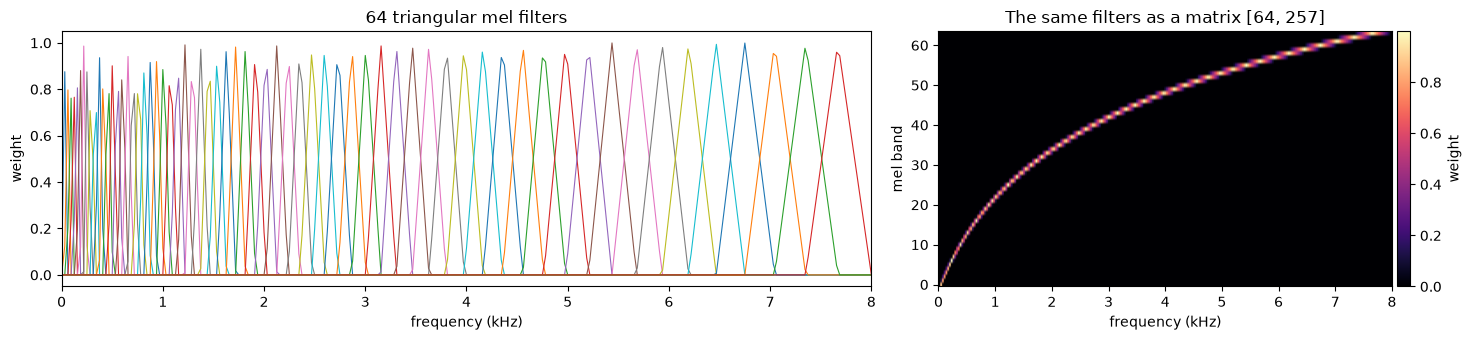

In [11]:
N_MELS = 64

# N_MELS + 2 edges, evenly spaced on the mel scale: band i rises from edge i, peaks at edge i + 1, falls to edge i + 2.
edges = mel_to_hz(np.linspace(hz_to_mel(0), hz_to_mel(SAMPLE_RATE / 2), N_MELS + 2))
lower, center, upper = edges[:-2, None], edges[1:-1, None], edges[2:, None]
rising = (bin_freqs - lower) / (center - lower)
falling = (upper - bin_freqs) / (upper - center)
filter_bank = np.maximum(0, np.minimum(rising, falling))  # [64 mel bands, 257 frequencies]
assert (filter_bank.sum(axis=1) > 0).all(), 'every band must cover at least one STFT frequency'
print('filter bank:', filter_bank.shape)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw={'width_ratios': [3, 2]})
for band in filter_bank:
    axes[0].plot(bin_freqs / 1000, band, lw=0.8)
axes[0].set(xlabel='frequency (kHz)', ylabel='weight', title=f'{N_MELS} triangular mel filters', xlim=(0, 8))
im = axes[1].imshow(filter_bank, origin='lower', aspect='auto', cmap='magma',
                    extent=[0, SAMPLE_RATE / 2000, -0.5, N_MELS - 0.5])
axes[1].set(xlabel='frequency (kHz)', ylabel='mel band', title='The same filters as a matrix [64, 257]')
plt.colorbar(im, ax=axes[1], label='weight', pad=0.01)
plt.tight_layout()
plt.show()

## 8. The mel spectrogram

Applying all filters to all frames is a single matrix multiplication: `[frames, 257] @ [257, 64] -> [frames, 64]`.
Then decibels again, as in step 5: this is the **log-mel spectrogram**.

mel spectrogram: (756, 64)


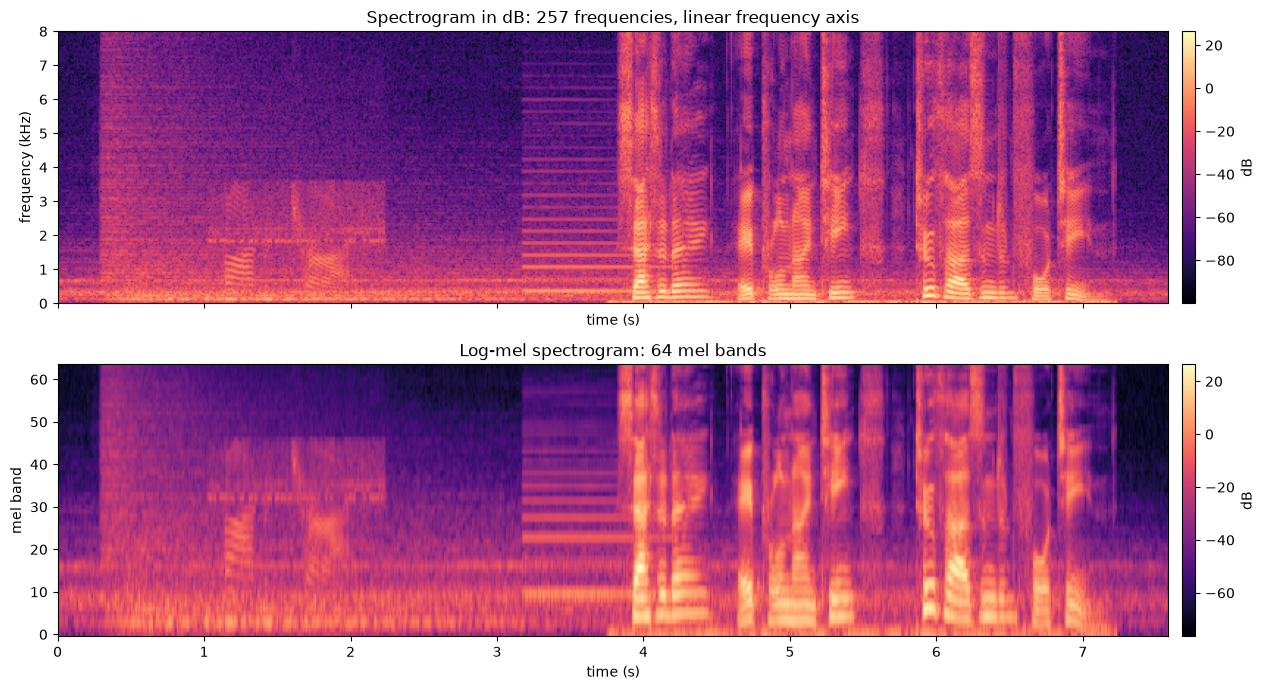

In [12]:
mel_power = power @ filter_bank.T              # [frames, 64]
log_mel = 10 * np.log10(mel_power + 1e-10)     # [frames, 64]
print('mel spectrogram:', mel_power.shape)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
show(power_db, f'Spectrogram in dB: {power.shape[1]} frequencies, linear frequency axis', colorbar='dB', ax=axes[0])
show(log_mel, f'Log-mel spectrogram: {N_MELS} mel bands', ylabel='mel band', extent_y=(-0.5, N_MELS - 0.5),
     colorbar='dB', ax=axes[1])
plt.tight_layout()
plt.show()

The log-mel spectrogram has 4 times fewer rows, and they are spent differently: the bottom of the plot (below 1 kHz,
where the pitch of the voice and its first harmonics are) now takes more than a third of the image, while 4-8 kHz is
squeezed into the top 16 bands. The harmonics of the speech are spread out and easier to see; the consonants at high
frequencies are still there, only compressed.

The y axis is now in mel bands. Their center frequencies are:

In [13]:
pd.Series(center[:, 0].round(), name='center (Hz)').rename_axis('mel band').iloc[::8]

mel band
0       28.0
8      292.0
16     653.0
24    1145.0
32    1816.0
40    2731.0
48    3979.0
56    5680.0
Name: center (Hz), dtype: float64

## Putting it together

The whole pipeline in one function, from a waveform `[samples]` to a log-mel spectrogram `[frames, mel bands]`. This
is what audio classification models (and speech recognition models like Whisper, which uses 80 bands) take as input:
an "image" with time and frequency axes, ready for a 2D CNN, or a **sequence** of 64-dimensional frames, one every
10 ms, ready for the 1D convolutions, recurrent layers and attention of this module.

In [14]:
def log_mel_spectrogram(wave, frame_length=FRAME_LENGTH, hop_length=HOP_LENGTH, n_fft=N_FFT, n_mels=N_MELS):
    frames = np.lib.stride_tricks.sliding_window_view(wave, frame_length)[::hop_length]   # [frames, frame_length]
    window = np.hanning(frame_length + 1)[:-1]
    power = np.abs(np.fft.rfft(frames * window, n=n_fft, axis=1)) ** 2                    # [frames, n_fft/2 + 1]
    freqs = np.fft.rfftfreq(n_fft, d=1 / SAMPLE_RATE)
    edges = mel_to_hz(np.linspace(0, hz_to_mel(SAMPLE_RATE / 2), n_mels + 2))
    lower, center, upper = edges[:-2, None], edges[1:-1, None], edges[2:, None]
    filter_bank = np.maximum(0, np.minimum((freqs - lower) / (center - lower), (upper - freqs) / (upper - center)))
    return 10 * np.log10(power @ filter_bank.T + 1e-10)                                  # [frames, n_mels]


assert np.allclose(log_mel_spectrogram(wave), log_mel)
log_mel_spectrogram(wave).shape

(756, 64)

PyTorch computes the same STFT (the Assignment 3 template uses `torch.stft`), with two differences in where the
frames are:

- With `win_length=400` and `n_fft=512`, `torch.stft` cuts 512-sample frames and puts the 400-sample window in their
  middle, so the windowed samples start $(512 - 400) / 2 = 56$ samples later than ours. We padded at the end instead.
  This changes the phase but not the magnitude.
- `center=False` starts the first frame at the first sample, like ours. The default `center=True` first pads the
  waveform so that frame $i$ is centered on sample $i \cdot \text{hop}$.

In [15]:
import torch

torch_stft = torch.stft(torch.tensor(wave), n_fft=N_FFT, hop_length=HOP_LENGTH, win_length=FRAME_LENGTH,
                        window=torch.hann_window(FRAME_LENGTH, dtype=torch.float64), center=False,
                        return_complex=True)  # [257, frames]: frequency first

offset = (N_FFT - FRAME_LENGTH) // 2
shifted = np.lib.stride_tricks.sliding_window_view(wave[offset:], FRAME_LENGTH)[::HOP_LENGTH]
ours = np.abs(np.fft.rfft(shifted * window, n=N_FFT, axis=1))
theirs = np.abs(torch_stft.numpy().T)
print('torch.stft:', tuple(torch_stft.shape), 'ours:', ours.shape,
      'max difference of magnitudes:', np.abs(theirs - ours[:len(theirs)]).max())

torch.stft: (257, 756) ours: (756, 257) max difference of magnitudes: 7.105427357601002e-15


## Choosing the frame length: time vs. frequency

The frame length decides what the spectrogram can resolve. A frame of $L$ samples can only tell apart frequencies
about $\text{sample rate} / L$ apart, and it can't tell *when* in the frame something happened. Short frames are sharp
in time and blurry in frequency, long frames the opposite. 25 ms is a compromise for speech.

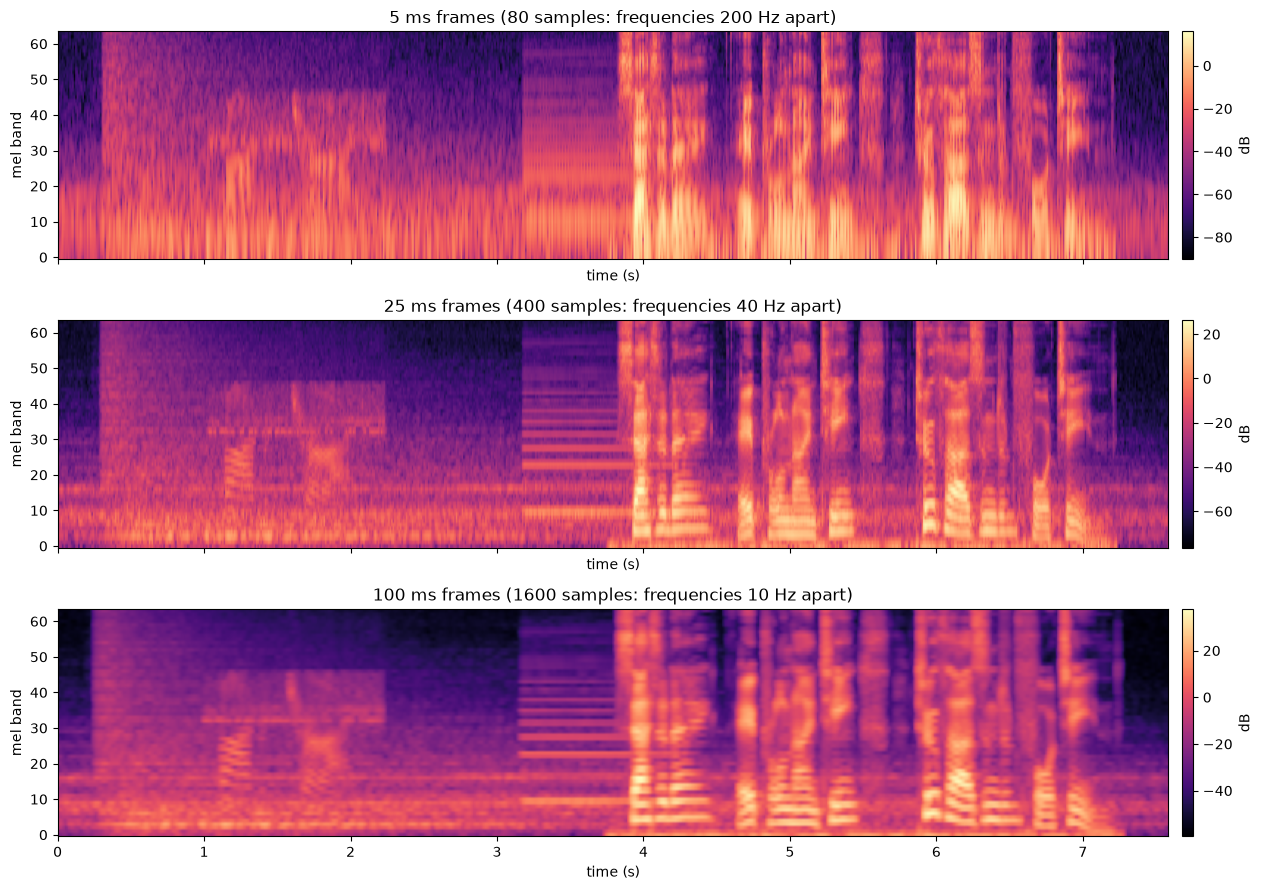

In [16]:
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for ax, ms in zip(axes, [5, 25, 100]):
    length = SAMPLE_RATE * ms // 1000
    n_fft = max(N_FFT, int(2 ** np.ceil(np.log2(length))))  # zero-pad short frames to 512, so all 64 bands get frequencies
    image = log_mel_spectrogram(wave, frame_length=length, n_fft=n_fft)
    show(image, f'{ms} ms frames ({length} samples: frequencies {SAMPLE_RATE / length:.0f} Hz apart)',
         ylabel='mel band', extent_y=(-0.5, N_MELS - 0.5), colorbar='dB', ax=ax)
plt.tight_layout()
plt.show()

With 5 ms frames the harmonics are gone (80 samples can only tell apart frequencies 200 Hz apart, more than the
spacing of the harmonics; zero-padding to 512 makes the plot smoother but adds no detail), while the start and end of
every sound are sharp. With 100 ms frames the harmonics are thin lines, even for the higher bands, but the words blur
into each other in time.

## In practice

Libraries compute the same thing in one call, with more options (normalization of the filters, a minimum
frequency, other mel formulas). In **torchaudio**, `MelSpectrogram` does steps 3-8 except the decibels, and
`AmplitudeToDB` does those. The defaults match our choices (Hann window, power, the same mel formula, filters
without normalization), and `center=False` places the frames like `torch.stft` above: so it should equal our
function applied to the waveform from sample 56 on.

torchaudio: (64, 756) ours: (756, 64) max difference: 0.0156 dB


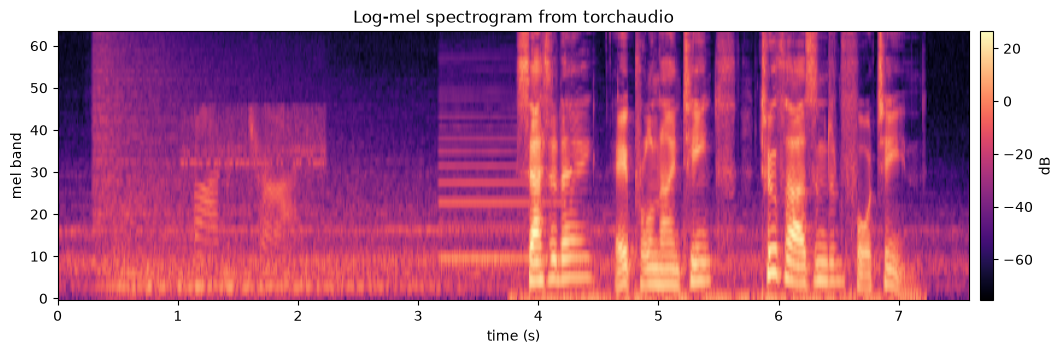

In [17]:
import torchaudio

mel_spectrogram = torchaudio.transforms.MelSpectrogram(
    sample_rate=SAMPLE_RATE, n_fft=N_FFT, win_length=FRAME_LENGTH, hop_length=HOP_LENGTH, n_mels=N_MELS, center=False)
to_db = torchaudio.transforms.AmplitudeToDB()  # 10 * log10(max(power, 1e-10))

torchaudio_log_mel = to_db(mel_spectrogram(torch.tensor(wave, dtype=torch.float32)))  # [64, frames]: bands first
ours = log_mel_spectrogram(wave[offset:])
print('torchaudio:', tuple(torchaudio_log_mel.shape), 'ours:', ours.shape,
      f'max difference: {np.abs(torchaudio_log_mel.numpy().T - ours[:torchaudio_log_mel.shape[1]]).max():.4f} dB')
show(torchaudio_log_mel.numpy().T, 'Log-mel spectrogram from torchaudio', ylabel='mel band',
     extent_y=(-0.5, N_MELS - 0.5), colorbar='dB')
plt.show()

The small difference comes from torchaudio computing in float32, we used float64. On a GPU, the same transform runs
on a whole batch of recordings at once: `mel_spectrogram.to(device)(waves)` with `waves` of shape
`[recordings, samples]` gives `[recordings, 64, frames]`.

With **librosa** (`%pip install librosa`), the same is
`librosa.power_to_db(librosa.feature.melspectrogram(y=wave, sr=16000, n_fft=512, win_length=400, hop_length=160,
n_mels=64, htk=True, norm=None, center=False))`: `htk=True` selects our mel formula and `norm=None` our unnormalized filters (librosa defaults to the Slaney versions of both).

Note that some models skip all of this: **wav2vec2**, the backbone of Assignment 3, takes the raw waveform and learns
its own front end, a 1D CNN that turns every 20 ms of audio into a feature vector.

**Things to try**

- Load other recordings (`load_recording('validate', i)`) and find the speech in their spectrograms.
- Change `N_MELS` to 16 or 128. What is lost with few bands? What happens with too many at the lowest frequencies?
- Skip the window (use `np.ones(FRAME_LENGTH)`) and compare the spectrograms.